In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df = pd.read_parquet('../data/raw/daily_weather.parquet')
print(df.shape)
print(df.head())

(27635763, 14)
  station_id city_name       date  season  avg_temp_c  min_temp_c  max_temp_c  \
0      41515  Asadabad 1957-07-01  Summer        27.0        21.1        35.6   
1      41515  Asadabad 1957-07-02  Summer        22.8        18.9        32.2   
2      41515  Asadabad 1957-07-03  Summer        24.3        16.7        35.6   
3      41515  Asadabad 1957-07-04  Summer        26.6        16.1        37.8   
4      41515  Asadabad 1957-07-05  Summer        30.8        20.0        41.7   

   precipitation_mm  snow_depth_mm  avg_wind_dir_deg  avg_wind_speed_kmh  \
0               0.0            NaN               NaN                 NaN   
1               0.0            NaN               NaN                 NaN   
2               1.0            NaN               NaN                 NaN   
3               4.1            NaN               NaN                 NaN   
4               0.0            NaN               NaN                 NaN   

   peak_wind_gust_kmh  avg_sea_level_pres

In [4]:
print(df.isnull().sum())

station_id                       0
city_name                    13993
date                             0
season                           0
avg_temp_c                 6230907
min_temp_c                 5718229
max_temp_c                 5539346
precipitation_mm           6642500
snow_depth_mm             24208615
avg_wind_dir_deg          24183195
avg_wind_speed_kmh        22350295
peak_wind_gust_kmh        26514277
avg_sea_level_pres_hpa    23618606
sunshine_total_min        26614302
dtype: int64


In [5]:
df = df.drop(columns=['snow_depth_mm', 'avg_wind_dir_deg', 'peak_wind_gust_kmh', 'avg_sea_level_pres_hpa', 'sunshine_total_min'])
print(df.shape)

(27635763, 9)


In [6]:
df=df.dropna(subset=['city_name'])
print(df.shape)

(27621770, 9)


In [7]:
num_cols = ['avg_temp_c', 'min_temp_c', 'max_temp_c', 'precipitation_mm', 'avg_wind_speed_kmh']
for col in num_cols:
    df[col] = df[col].fillna(df[col].median())
print(df.isnull().sum())

station_id            0
city_name             0
date                  0
season                0
avg_temp_c            0
min_temp_c            0
max_temp_c            0
precipitation_mm      0
avg_wind_speed_kmh    0
dtype: int64


In [8]:
df['month'] = df['date'].dt.month
df['day'] = df['date'].dt.day
df['year'] = df['date'].dt.year
print(df.head())

  station_id city_name       date  season  avg_temp_c  min_temp_c  max_temp_c  \
0      41515  Asadabad 1957-07-01  Summer        27.0        21.1        35.6   
1      41515  Asadabad 1957-07-02  Summer        22.8        18.9        32.2   
2      41515  Asadabad 1957-07-03  Summer        24.3        16.7        35.6   
3      41515  Asadabad 1957-07-04  Summer        26.6        16.1        37.8   
4      41515  Asadabad 1957-07-05  Summer        30.8        20.0        41.7   

   precipitation_mm  avg_wind_speed_kmh  month  day  year  
0               0.0                10.9      7    1  1957  
1               0.0                10.9      7    2  1957  
2               1.0                10.9      7    3  1957  
3               4.1                10.9      7    4  1957  
4               0.0                10.9      7    5  1957  


In [9]:
df['will_rain'] = (df['precipitation_mm'] > 0).astype(int)
print(df['will_rain'].value_counts())
print("Rain days %:", round(df['will_rain'].mean() * 100, 2))

will_rain
0    20009891
1     7611879
Name: count, dtype: int64
Rain days %: 27.56


In [10]:
print("Final dataframe:")
print(df.shape)
print(df.columns.tolist())
print(df.dtypes)

Final dataframe:
(27621770, 13)
['station_id', 'city_name', 'date', 'season', 'avg_temp_c', 'min_temp_c', 'max_temp_c', 'precipitation_mm', 'avg_wind_speed_kmh', 'month', 'day', 'year', 'will_rain']
station_id                  category
city_name                   category
date                  datetime64[us]
season                      category
avg_temp_c                   float64
min_temp_c                   float64
max_temp_c                   float64
precipitation_mm             float64
avg_wind_speed_kmh           float64
month                          int32
day                            int32
year                           int32
will_rain                      int64
dtype: object


In [11]:
import os
os.makedirs('../data/processed', exist_ok=True)
df.to_csv('../data/processed/weather_clean.csv', index=False)
print("saved! rows:", len(df))

saved! rows: 27621770


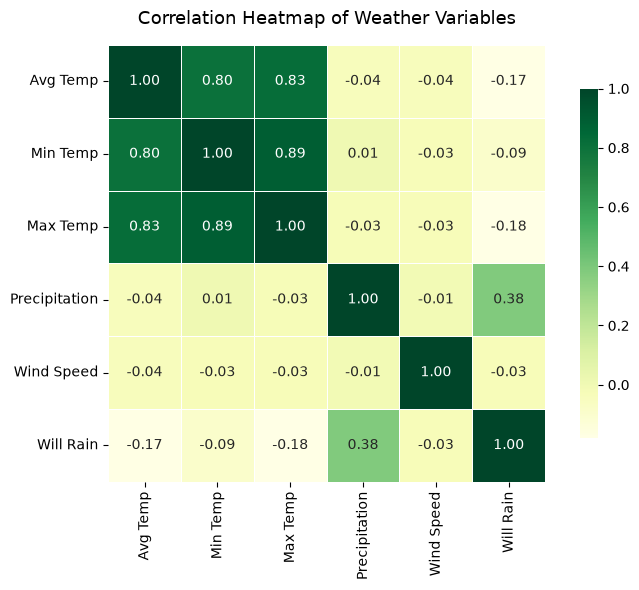

Saved: c:\Users\SAMPATH\Desktop\weathergpt-ml\notebooks\correlation_heatmap.png


In [2]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load only 50,000 rows to save memory
BASE_DIR = os.path.dirname(os.getcwd())
cols = ['avg_temp_c', 'min_temp_c', 'max_temp_c',
        'precipitation_mm', 'avg_wind_speed_kmh', 'will_rain']

df = pd.read_csv(
    os.path.join(BASE_DIR, 'data', 'processed', 'weather_clean.csv'),
    usecols=cols,
    nrows=50000
).dropna()

# Rename for cleaner labels
df.columns = ['Avg Temp', 'Min Temp', 'Max Temp',
              'Precipitation', 'Wind Speed', 'Will Rain']

# Correlation heatmap
corr = df.corr()
plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='YlGn',
            linewidths=0.5, square=True,
            cbar_kws={'shrink': 0.8})
plt.title('Correlation Heatmap of Weather Variables', fontsize=13, pad=15)
plt.tight_layout()

save_path = os.path.join(os.getcwd(), 'correlation_heatmap.png')
plt.savefig(save_path, dpi=150, bbox_inches='tight')
plt.show()
print(f"Saved: {save_path}")
